In [ ]:
!nvidia-smi

Wed Sep 23 04:34:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   59C    P0             28W /   70W |     135MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip install -q ultralytics opencv-python

In [ ]:
from ultralytics import YOLO
import cv2
import os

print("Setup complete!")

Setup complete!


In [ ]:
model = YOLO("yolo11n.pt")

print("YOLO loaded successfully!")

YOLO loaded successfully!


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'yolo11n.pt', 'Ronaldo bicycle kick 4k (Free clip) No watermark.mp4', 'sample_data']


In [ ]:
results = model.predict(
    source="/content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4",
    classes=[0],
    conf=0.30,
    save=True
)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/556) /content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4: 384x640 13 persons, 10.0ms
video 1/1 (frame 2/556) /content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4: 384x640 13 persons, 10.0ms
video 1/1 (frame 3/556) /content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4: 384x640 11 persons, 14.0ms
video 1/1 (frame 4/556) /content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4: 384x640 11 persons, 8.7ms
vide

In [ ]:
!find /content/runs -type f

/content/runs/detect/predict/Ronaldo bicycle kick 4k (Free clip) No watermark.avi


In [ ]:
from IPython.display import Video, display

display(Video(
    "/content/runs/detect/predict/football_test.avi",
    embed=True
))

In [ ]:
from IPython.display import Video, display

display(Video(
    "/content/yolo11n.pt",
    embed=True
))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
!find /content/runs -type f

/content/runs/detect/predict/Ronaldo bicycle kick 4k (Free clip) No watermark.avi


In [ ]:
import cv2
import os

video_path = "/content/runs/detect/predict/Ronaldo bicycle kick 4k (Free clip) No watermark.avi"

cap = cv2.VideoCapture(video_path)

print("File exists:", os.path.exists(video_path))
print("Opened:", cap.isOpened())
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

cap.release()

File exists: True
Opened: True
Frames: 553
FPS: 30.0
Width: 1280
Height: 720


In [ ]:
!ffmpeg -y -i "/content/runs/detect/predict/Ronaldo bicycle kick 4k (Free clip) No watermark.avi" \
-c:v libx264 -preset fast -crf 23 \
"/content/football_result.mp4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
from IPython.display import Video

Video("/content/football_result.mp4", embed=True, width=900)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

video_path = "/content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4"

results = model.track(
    source=video_path,
    classes=[0],             # Person class
    conf=0.30,
    tracker="bytetrack.yaml",
    persist=True,
    save=True
)

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 316ms
Prepared 1 package in 63ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.8s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/556) /content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4: 384x640 13 pers

In [ ]:
!find /content/runs -type f

/content/runs/detect/track/Ronaldo bicycle kick 4k (Free clip) No watermark.avi
/content/runs/detect/predict/Ronaldo bicycle kick 4k (Free clip) No watermark.avi


In [ ]:
!ffmpeg -y \
-i "/content/runs/track/Ronaldo bicycle kick 4k (Free clip) No watermark.avi" \
-c:v libx264 -preset fast -crf 23 \
"/content/tracked_football.mp4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
!ffmpeg -y \
-i "/content/runs/detect/track/Ronaldo bicycle kick 4k (Free clip) No watermark.avi" \
-c:v libx264 -preset fast -crf 23 \
"/content/tracked_football.mp4"

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [ ]:
from IPython.display import Video

Video(
    "/content/tracked_football.mp4",
    embed=True,
    width=900
)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
#above is the baseline model

In [ ]:
#Player Trajectory Extraction and Movement Analysis

In [ ]:
from ultralytics import YOLO
import cv2
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

model = YOLO("yolo11n.pt")

video_path = "/content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4"

print("Ready!")

Ready!


In [ ]:
track_history = defaultdict(list)

results = model.track(
    source=video_path,
    classes=[0],
    conf=0.30,
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    verbose=False
)

frame_number = 0

for result in results:
    frame_number += 1

    if result.boxes is None or result.boxes.id is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    track_ids = result.boxes.id.int().cpu().tolist()

    for box, track_id in zip(boxes, track_ids):

        x1, y1, x2, y2 = box

        # Bottom-centre of bounding box
        x = (x1 + x2) / 2
        y = y2

        track_history[track_id].append(
            (frame_number, float(x), float(y))
        )

print("Processing complete!")
print("Frames processed:", frame_number)
print("Unique tracking IDs:", len(track_history))

Processing complete!
Frames processed: 553
Unique tracking IDs: 87


In [ ]:
for track_id, positions in list(track_history.items())[:5]:
    print(f"\nPlayer ID {track_id}")
    print("Number of tracked frames:", len(positions))
    print("First 5 positions:", positions[:5])


Player ID 1
Number of tracked frames: 96
First 5 positions: [(1, 502.602294921875, 507.64447021484375), (2, 502.605712890625, 507.5155029296875), (3, 502.6817626953125, 506.1094970703125), (4, 502.40887451171875, 504.86053466796875), (5, 502.4014892578125, 505.05621337890625)]

Player ID 2
Number of tracked frames: 56
First 5 positions: [(1, 1018.4277954101562, 429.9134521484375), (2, 1019.556396484375, 429.6157531738281), (3, 1023.47607421875, 429.86138916015625), (4, 1027.1329345703125, 431.2262268066406), (5, 1029.70556640625, 431.8543395996094)]

Player ID 3
Number of tracked frames: 98
First 5 positions: [(1, 895.45556640625, 374.634765625), (2, 896.2911376953125, 374.7487487792969), (3, 897.505126953125, 377.1974792480469), (4, 898.73828125, 377.05816650390625), (5, 900.2725830078125, 376.7461242675781)]

Player ID 4
Number of tracked frames: 65
First 5 positions: [(1, 595.7838134765625, 380.54278564453125), (2, 595.96630859375, 380.9679260253906), (3, 596.169921875, 381.4272155

In [ ]:
model = YOLO("yolo11n.pt")

results = model.track(
    source=video_path,
    classes=[0],
    conf=0.30,
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    verbose=False
)

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

output_path = "/content/player_trajectories.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    output_path,
    fourcc,
    fps,
    (width, height)
)

trajectory_history = defaultdict(list)

for result in results:

    frame = result.orig_img.copy()

    if result.boxes is not None and result.boxes.id is not None:

        boxes = result.boxes.xyxy.cpu().numpy()
        track_ids = result.boxes.id.int().cpu().tolist()

        for box, track_id in zip(boxes, track_ids):

            x1, y1, x2, y2 = map(int, box)

            # Approximate player's position on the pitch
            x = int((x1 + x2) / 2)
            y = int(y2)

            trajectory_history[track_id].append((x, y))

            # Keep only recent positions
            if len(trajectory_history[track_id]) > 60:
                trajectory_history[track_id].pop(0)

            # Bounding box
            cv2.rectangle(
                frame,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            # ID
            cv2.putText(
                frame,
                f"ID {track_id}",
                (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

            # Draw trajectory
            points = trajectory_history[track_id]

            for i in range(1, len(points)):

                cv2.line(
                    frame,
                    points[i - 1],
                    points[i],
                    (0, 0, 255),
                    2
                )

    writer.write(frame)

writer.release()

print("Trajectory video created!")
print(output_path)

Trajectory video created!
/content/player_trajectories.mp4


In [ ]:
!ffmpeg -y -i "/content/player_trajectories.mp4" \
-c:v libx264 -preset fast -crf 23 \
"/content/player_trajectories_colab.mp4" \
-loglevel error

In [ ]:
from IPython.display import Video

Video(
    "/content/player_trajectories_colab.mp4",
    embed=True,
    width=900
)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
longest_track_id = max(
    track_history,
    key=lambda k: len(track_history[k])
)

print("Longest tracked player ID:", longest_track_id)
print(
    "Frames tracked:",
    len(track_history[longest_track_id])
)

Longest tracked player ID: 305
Frames tracked: 152


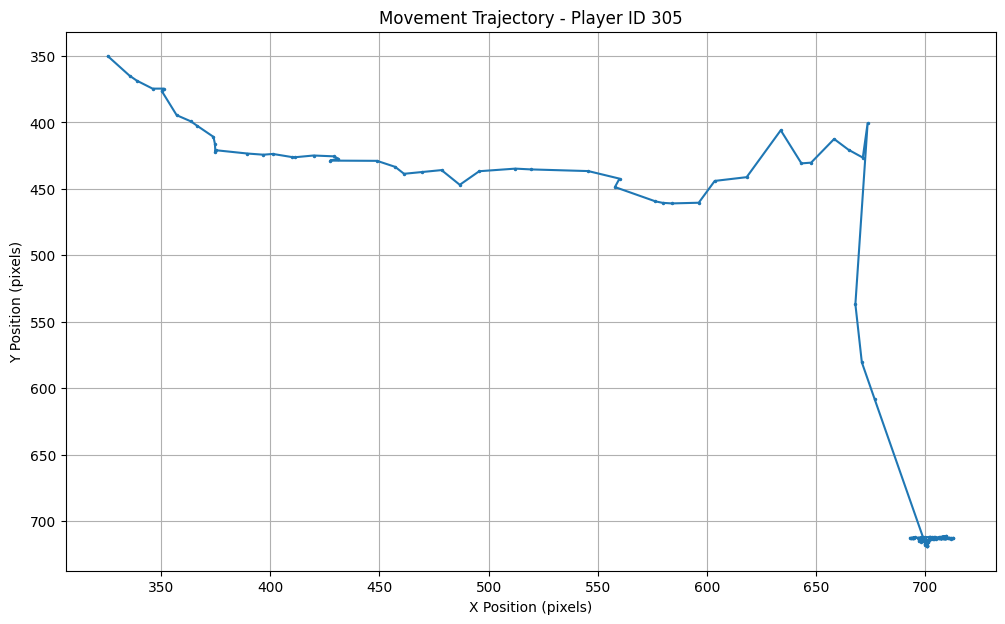

In [ ]:
positions = track_history[longest_track_id]

x_positions = [p[1] for p in positions]
y_positions = [p[2] for p in positions]

plt.figure(figsize=(12, 7))

plt.plot(
    x_positions,
    y_positions,
    marker=".",
    markersize=3
)

plt.gca().invert_yaxis()

plt.title(
    f"Movement Trajectory - Player ID {longest_track_id}"
)

plt.xlabel("X Position (pixels)")
plt.ylabel("Y Position (pixels)")

plt.grid()

plt.show()

In [ ]:
#Saving Baseline Results

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/Football_CV_Project")

folders = [
    PROJECT_ROOT / "notebooks",
    PROJECT_ROOT / "data/raw/custom_clips",
    PROJECT_ROOT / "data/raw/soccernet",
    PROJECT_ROOT / "data/processed/clips",
    PROJECT_ROOT / "data/processed/frames",
    PROJECT_ROOT / "data/processed/annotations",
    PROJECT_ROOT / "models/pretrained",
    PROJECT_ROOT / "models/trained",
    PROJECT_ROOT / "outputs/baseline",
    PROJECT_ROOT / "outputs/tracking",
    PROJECT_ROOT / "outputs/trajectories",
    PROJECT_ROOT / "outputs/pitch_mapping",
    PROJECT_ROOT / "outputs/heatmaps",
    PROJECT_ROOT / "docs/results",
    PROJECT_ROOT / "docs/figures",
]

for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

print("Project structure created successfully!")
print(PROJECT_ROOT)

Project structure created successfully!
/content/drive/MyDrive/Football_CV_Project


In [ ]:
from pathlib import Path

files_to_check = [
    "/content/football_result.mp4",
    "/content/tracked_football.mp4",
    "/content/player_trajectories.mp4",
    "/content/player_trajectories_colab.mp4",
    "/content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4"
]

for file in files_to_check:
    p = Path(file)

    if p.exists():
        size_mb = p.stat().st_size / (1024 ** 2)
        print(f"FOUND: {p.name} ({size_mb:.1f} MB)")
    else:
        print(f"NOT FOUND: {p.name}")

FOUND: football_result.mp4 (12.9 MB)
FOUND: tracked_football.mp4 (12.7 MB)
FOUND: player_trajectories.mp4 (46.9 MB)
FOUND: player_trajectories_colab.mp4 (11.8 MB)
FOUND: Ronaldo bicycle kick 4k (Free clip) No watermark.mp4 (5.4 MB)


In [ ]:
import shutil

BASELINE_OUTPUT = PROJECT_ROOT / "outputs/baseline"

baseline_files = [
    "/content/football_result.mp4",
    "/content/tracked_football.mp4",
    "/content/player_trajectories.mp4",
    "/content/player_trajectories_colab.mp4"
]

for file in baseline_files:

    source = Path(file)

    if source.exists():

        destination = BASELINE_OUTPUT / source.name

        shutil.copy2(source, destination)

        print("Saved:", destination)

Saved: /content/drive/MyDrive/Football_CV_Project/outputs/baseline/football_result.mp4
Saved: /content/drive/MyDrive/Football_CV_Project/outputs/baseline/tracked_football.mp4
Saved: /content/drive/MyDrive/Football_CV_Project/outputs/baseline/player_trajectories.mp4
Saved: /content/drive/MyDrive/Football_CV_Project/outputs/baseline/player_trajectories_colab.mp4


In [ ]:
CUSTOM_CLIPS = PROJECT_ROOT / "data/raw/custom_clips"

ronaldo_video = Path(
    "/content/Ronaldo bicycle kick 4k (Free clip) No watermark.mp4"
)

if ronaldo_video.exists():

    destination = CUSTOM_CLIPS / "ronaldo_bicycle_kick_baseline.mp4"

    shutil.copy2(
        ronaldo_video,
        destination
    )

    print("Original test video saved:")
    print(destination)

else:
    print("Original Ronaldo video was not found.")

Original test video saved:
/content/drive/MyDrive/Football_CV_Project/data/raw/custom_clips/ronaldo_bicycle_kick_baseline.mp4


In [ ]:
print("PROJECT FILES\n")

for path in PROJECT_ROOT.rglob("*"):
    if path.is_file():
        size_mb = path.stat().st_size / (1024 ** 2)

        print(
            path.relative_to(PROJECT_ROOT),
            f"- {size_mb:.1f} MB"
        )

PROJECT FILES

notebooks/01_Baseline_Detection_Tracking.ipynb - 0.2 MB
outputs/baseline/football_result.mp4 - 12.9 MB
outputs/baseline/tracked_football.mp4 - 12.7 MB
outputs/baseline/player_trajectories.mp4 - 46.9 MB
outputs/baseline/player_trajectories_colab.mp4 - 11.8 MB
data/raw/custom_clips/ronaldo_bicycle_kick_baseline.mp4 - 5.4 MB
